# Install

In [1]:
# !pip install hazm
# !pip install python-bidi
# !pip install arabic-reshaper

# Libraries

In [2]:
import pylab as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import seaborn as sns


from collections import Counter
from hazm import *

# persian transformer
from bidi.algorithm import get_display
import arabic_reshaper

# sklearn package
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import KFold
from sklearn import svm
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Data load and structure

In [3]:
data = pd.read_excel("Data-text.xlsx")

print('Data shape is: ', data.shape)
data.head()

Data shape is:  (12015, 2)


,عنوان,متن
0,ادب و هنر,\nجاودانگي در زندگي گروهي از طريق هنر \nنگاهي ...
1,ادب و هنر,\nرويدادهاي هنري جهان \nنمايشگاه هنر در خدمت د...
2,ادب و هنر,\nبرديوار نگارخانه ها \nگالري گلستان: \nنمايشگ...
3,اجتماعی,\nبازي را جدي بگيريم \nمطالعه اي مقدماتي پيرام...
4,علمی فرهنگی,\nتخته سياه و غباري كه سترده نمي شود... \nاشار...


# Plot distribution of topics in train corpus

In [4]:
# plot for persian is not OK so this function solve the problem
def make_farsi_text(x):
    output = []
    for i in x:
        reshaped_text = arabic_reshaper.reshape(i)
        farsi_text = get_display(reshaped_text)
        output.append(farsi_text)
    return output


In [5]:
def barplot(data):
    dfToList = data.iloc[:, 0].tolist()  # first column contains the text data

    # Find number of each news topic
    counts = Counter(dfToList)
    
        
    plt.figure(figsize=(20, 8))  

    # Create the bar plot
    X = np.arange(len(counts))
    plt.bar(X, counts.values(), align='center', width=0.5, color=['royalblue'])
    plt.xticks(X, make_farsi_text(counts.keys()))
    ymax = max(counts.values()) + 300
    plt.ylim(0, ymax)
    plt.savefig('topic.png')
    plt.show()

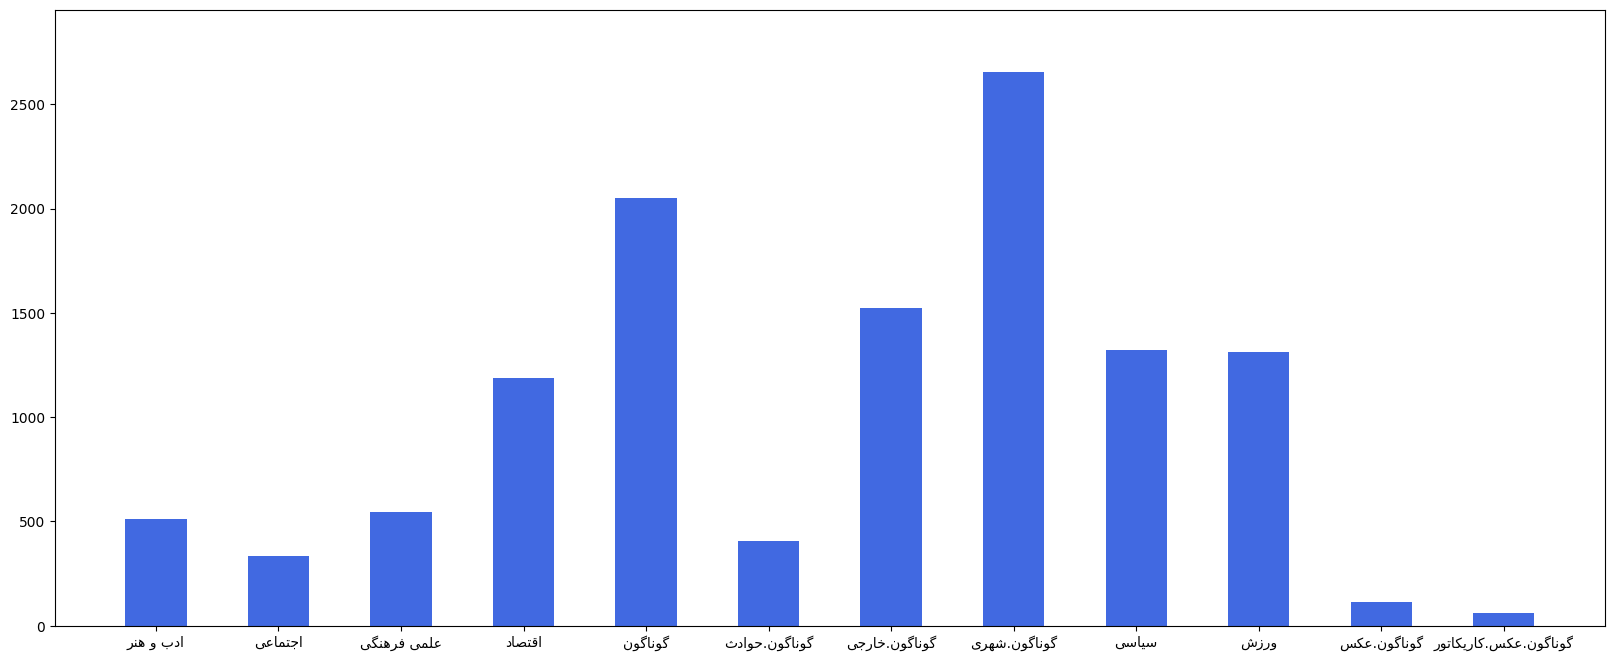

In [6]:
barplot(data)

# Preprocess of data

In [7]:
def preprocessing(data):
    stopwords = stopwords_list()
    normalizer = Normalizer()
    lemmatizer = Lemmatizer()
    puncList = [".", ";", ":", "!", "?", "/", "\\", ",", "#", "@", "$", "&", ")", "(", "\"", "\'\'"]
    stopwords.extend(puncList)

    for i in range(len(data)):
        text = str(data.iloc[i, 1])  # Ensure the text is a string
        text = normalizer.normalize(text)
        text = word_tokenize(text)
        text = [lemmatizer.lemmatize(w) for w in text if w not in stopwords]
        data.iloc[i, 1] = ' '.join(text)  # Join tokens back to a single string

    return data

# Feature Extraction by TF-IDF

In [8]:
def prepare_data(data):
    data = preprocessing(data)
    X = data.iloc[:, 1].tolist()
    y = data.iloc[:, 0].tolist()

    # Convert labels to numbers
    label_encoder = LabelEncoder()
    y = label_encoder.fit_transform(y)

    # CountVectorize each document into 3000 features of words by its tf-idf
    countV = CountVectorizer(min_df=2, max_features=3000, lowercase=False)
    X = countV.fit_transform(X)
    tfidf = TfidfTransformer()
    X = tfidf.fit_transform(X)

    return X, y, label_encoder, countV, tfidf
    

# Save & Load Preprocessed Data

In [9]:
def save_preprocessed_data(X, y, label_encoder, countV, tfidf):
    with open('X.pickle', 'wb') as output:
        pickle.dump(X, output)
    with open('y.pickle', 'wb') as output:
        pickle.dump(y, output)
    with open('label_encoder.pickle', 'wb') as output:
        pickle.dump(label_encoder, output)
    with open('countV.pickle', 'wb') as output:
        pickle.dump(countV, output)
    with open('tfidf.pickle', 'wb') as output:
        pickle.dump(tfidf, output)

def load_preprocessed_data():
    with open('X.pickle', 'rb') as data:
        X = pickle.load(data)
    with open('y.pickle', 'rb') as data:
        y = pickle.load(data)
    with open('label_encoder.pickle', 'rb') as data:
        label_encoder = pickle.load(data)
    with open('countV.pickle', 'rb') as data:
        countV = pickle.load(data)
    with open('tfidf.pickle', 'rb') as data:
        tfidf = pickle.load(data)
    
    return X, y, label_encoder, countV, tfidf

In [10]:
def main():
    X, y, label_encoder, countV, tfidf = prepare_data(data)
    save_preprocessed_data(X, y, label_encoder, countV, tfidf)

if __name__ == "__main__":
    main()

# Define 5-Fold Cross-Validation

In [11]:
def cross_validate_model(X, y, model, n_splits=5, n_repeats=5):
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    accuracies = []

    for _ in range(n_repeats):
        for train_index, test_index in kf.split(X):
            X_train, X_test = X[train_index], X[test_index]
            y_train, y_test = y[train_index], y[test_index]

            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            accuracies.append(accuracy_score(y_test, y_pred))

    return np.mean(accuracies), np.std(accuracies)

# Trying different classifiers:

# 1

---


**MultinomialNB Model:**

In [26]:
def main():
    X, y, label_encoder, countV, tfidf = load_preprocessed_data()
    # Cross-validate MultinomialNB
    nb_model = MultinomialNB()
    mean_accuracy_nb, std_accuracy_nb = cross_validate_model(X, y, nb_model)
    print(f'MultinomialNB - Average Accuracy: {mean_accuracy_nb:.4f}')
    print(f'MultinomialNB - Standard Deviation of Accuracy: {std_accuracy_nb:.4f}')

if __name__ == "__main__":
    main()

MultinomialNB - Average Accuracy: 0.7318
MultinomialNB - Standard Deviation of Accuracy: 0.0122


# 2

---


**RandomForest Model :**

In [13]:
def main():
    X, y, label_encoder, countV, tfidf = load_preprocessed_data()
    # Cross-validate RandomForestClassifier
    rfc_model = RandomForestClassifier(
        bootstrap=False, class_weight=None, criterion='gini',
        max_depth=40, max_features='sqrt', max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        min_samples_leaf=1, min_samples_split=5,
        min_weight_fraction_leaf=0.0, n_estimators=10, n_jobs=1,
        oob_score=False, random_state=8, verbose=0, warm_start=False
    )
    mean_accuracy_rfc, std_accuracy_rfc = cross_validate_model(X, y, rfc_model)
    print(f'RandomForest - Average Accuracy: {mean_accuracy_rfc:.4f}')
    print(f'RandomForest - Standard Deviation of Accuracy: {std_accuracy_rfc:.4f}')
    
    # Save preprocessed data to pickle
    save_preprocessed_data(X, y, label_encoder, countV, tfidf)

    # Save trained RandomForest model
    with open('model-RFC.pickle', 'wb') as output:
        pickle.dump(rfc_model, output)
    
    # Save RandomForest model results
    rfc_results = {
        'Model': 'Random Forest',
        'Average Accuracy': mean_accuracy_rfc,
        'Standard Deviation of Accuracy': std_accuracy_rfc
    }
    df_models_rfc = pd.DataFrame(rfc_results, index=[0])
    with open('model-RFC-result.pickle', 'wb') as output:
        pickle.dump(df_models_rfc, output)

if __name__ == "__main__":
    main()

RandomForest - Average Accuracy: 0.7536
RandomForest - Standard Deviation of Accuracy: 0.0058


# 3

---


**KNN model:**

In [15]:
def main():
    X, y, label_encoder, countV, tfidf = load_preprocessed_data()
    # Cross-validate KNeighborsClassifier
    knn_model = KNeighborsClassifier(
        algorithm='auto', leaf_size=30, metric='minkowski',
        metric_params=None, n_jobs=1, n_neighbors=6, p=2,
        weights='uniform'
    )
    
    mean_accuracy_knn, std_accuracy_knn = cross_validate_model(X, y, knn_model)
    print(f'KNN - Average Accuracy: {mean_accuracy_knn:.4f}')
    print(f'KNN - Standard Deviation of Accuracy: {std_accuracy_knn:.4f}')

    # Save KNeighborsClassifier model
    with open('model-KNN.pickle', 'wb') as output:
        pickle.dump(knn_model, output)

if __name__ == "__main__":
    main()

KNN - Average Accuracy: 0.7163
KNN - Standard Deviation of Accuracy: 0.0100


# 4

---


**SVM Model:**

In [16]:
def main():
    X, y, label_encoder, countV, tfidf = load_preprocessed_data()
    # Cross-validate SVM
    svm_model = svm.SVC(
        C=0.1, cache_size=20, class_weight=None, coef0=0.0,
        decision_function_shape='ovr', degree=3, gamma='auto', kernel='linear',
        max_iter=-1, probability=True, random_state=8, shrinking=True, tol=0.001,
        verbose=False
    )
    
    mean_accuracy_svm, std_accuracy_svm = cross_validate_model(X, y, svm_model)
    print(f'SVM - Average Accuracy: {mean_accuracy_svm:.4f}')
    print(f'SVM - Standard Deviation of Accuracy: {std_accuracy_svm:.4f}')

    # Save SVM model
    with open('model-SVM.pickle', 'wb') as output:
        pickle.dump(svm_model, output)

if __name__ == "__main__":
    main()

SVM - Average Accuracy: 0.7278
SVM - Standard Deviation of Accuracy: 0.0102


or

In [ ]:
def main():
    X, y, label_encoder, countV, tfidf = load_preprocessed_data()
    # Cross-validate SVM
    print("Starting SVM cross-validation")
    svm_model = svm.SVC(
        C=0.1, cache_size=200, class_weight=None, coef0=0.0,
        decision_function_shape='ovr', degree=3, gamma='auto', kernel='linear',
        max_iter=-1, probability=True, random_state=8, shrinking=True, tol=0.001,
        verbose=True  # Set verbose to True for SVM
    )
    
    mean_accuracy_svm, std_accuracy_svm = cross_validate_model(X, y, svm_model)
    print(f'SVM - Average Accuracy: {mean_accuracy_svm:.4f}')
    print(f'SVM - Standard Deviation of Accuracy: {std_accuracy_svm:.4f}')

    # Save SVM model
    with open('model-SVM.pickle', 'wb') as output:
        pickle.dump(svm_model, output)

if __name__ == "__main__":
    main()

# 5

---


**Multinomial Logistic Regression Model:**

In [17]:
def main():
    X, y, label_encoder, countV, tfidf = load_preprocessed_data()
    # Cross-validate LogisticRegression
    print("Starting Logistic Regression cross-validation")
    lr_model = LogisticRegression(
        C=1.0, class_weight='balanced', dual=False,
        fit_intercept=True, intercept_scaling=1, max_iter=100,
        multi_class='multinomial', n_jobs=1, penalty='l2',
        random_state=8, solver='sag', tol=0.0001, verbose=0,
        warm_start=False
    )
    
    mean_accuracy_lr, std_accuracy_lr = cross_validate_model(X, y, lr_model)
    print(f'Logistic Regression - Average Accuracy: {mean_accuracy_lr:.4f}')
    print(f'Logistic Regression - Standard Deviation of Accuracy: {std_accuracy_lr:.4f}')

    # Save LogisticRegression model
    with open('model-LR.pickle', 'wb') as output:
        pickle.dump(lr_model, output)

if __name__ == "__main__":
    main()

Starting Logistic Regression cross-validation
Logistic Regression - Average Accuracy: 0.7613
Logistic Regression - Standard Deviation of Accuracy: 0.0087


# 6
---


**Gradient Boosting Machine Model:**

In [18]:
def main():
    X, y, label_encoder, countV, tfidf = load_preprocessed_data()
    # Cross-validate GradientBoostingClassifier
    print("Starting Gradient Boosting cross-validation")
    gb_model = GradientBoostingClassifier(
        criterion='friedman_mse', init=None,
        learning_rate=0.1, loss='log_loss', max_depth=15,
        max_features='sqrt', max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        min_samples_leaf=2, min_samples_split=50,
        min_weight_fraction_leaf=0.0, n_estimators=10,
        random_state=8, subsample=1.0, verbose=0,
        warm_start=False
    )
    
    mean_accuracy_gb, std_accuracy_gb = cross_validate_model(X, y, gb_model)
    print(f'Gradient Boosting - Average Accuracy: {mean_accuracy_gb:.4f}')
    print(f'Gradient Boosting - Standard Deviation of Accuracy: {std_accuracy_gb:.4f}')

    # Save GradientBoostingClassifier model
    with open('model-GB.pickle', 'wb') as output:
        pickle.dump(gb_model, output)

if __name__ == "__main__":
    main()

Starting Gradient Boosting cross-validation
Gradient Boosting - Average Accuracy: 0.7330
Gradient Boosting - Standard Deviation of Accuracy: 0.0049


# Best Model Analysis

              precision    recall  f1-score   support

           0       0.71      1.00      0.83        65
           1       0.73      0.95      0.83       110
           2       0.84      0.93      0.88       232
           3       0.84      0.79      0.82       262
           4       0.67      0.87      0.76       105
           5       0.95      0.98      0.97       255
           6       0.79      0.63      0.70       390
           7       0.41      0.84      0.55        83
           8       0.93      0.95      0.94       303
           9       0.92      0.71      0.81       559
          10       0.97      1.00      0.98        29
          11       1.00      1.00      1.00        10

    accuracy                           0.82      2403
   macro avg       0.81      0.89      0.84      2403
weighted avg       0.85      0.82      0.82      2403

Logistic Regression Test Set Accuracy: 0.8223


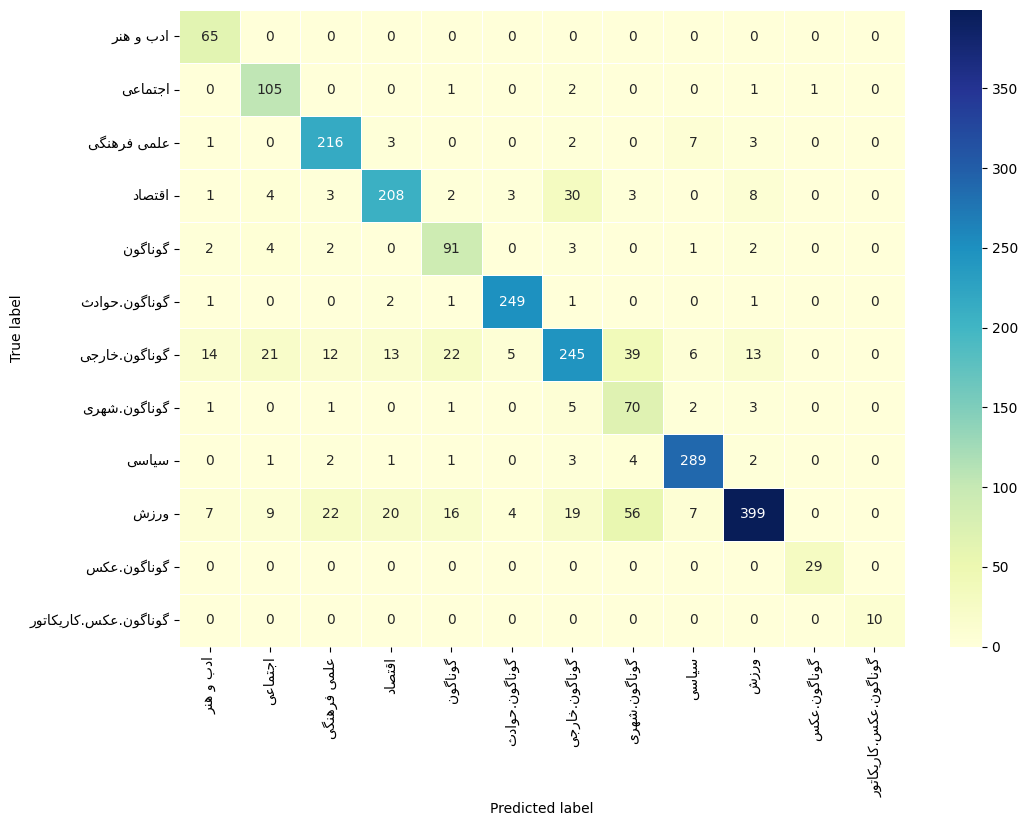

In [19]:
def logistic_regression_analysis():
    with open('model-LR.pickle', 'rb') as data:
        classifier = pickle.load(data)

    # Load preprocessed data to get X_test and y_test
    X, y, label_encoder, countV, tfidf = load_preprocessed_data()

    # Split data for evaluation
    kf = KFold(n_splits=5, shuffle=True, random_state=8)
    for train_index, test_index in kf.split(X):
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]
        break

    y_pred = classifier.predict(X_test)

    print(classification_report(y_test, y_pred))
    print(f'Logistic Regression Test Set Accuracy: {accuracy_score(y_test, y_pred):.4f}')

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    labels = ['ادب و هنر', 'اجتماعی', 'علمی فرهنگی', 'اقتصاد', 'گوناگون', 'گوناگون.حوادث', 'گوناگون.خارجی', 'گوناگون.شهری', 'سیاسی', 'ورزش', 'گوناگون.عکس', 'گوناگون.عکس.کاریکاتور']

    fig, ax = plt.subplots(figsize=(11.7, 8.27))
    df_cm = pd.DataFrame(cm,index=make_farsi_text(labels),columns=make_farsi_text(labels))
    sns.heatmap(df_cm, annot=True, cmap="YlGnBu", fmt='g', linewidths=0.5, ax=ax)
    ax.set(xlabel='Predicted label', ylabel='True label')
    plt.savefig('ConfMatrix.png')
    plt.show()

if __name__ == "__main__":
    logistic_regression_analysis()